# CIFAR-10 Image Classification Using ANN

This notebook follows the complete workflow:

1. Import libraries
2. Load the CIFAR-10 dataset
3. Split the data into training, validation, and test sets
4. Create an Artificial Neural Network (ANN)
5. Train the model
6. Test and evaluate the model
7. Predict the class of an external image (JPG/PNG)

**Note:** This is a fully connected ANN, not a CNN. CIFAR-10 contains 10 classes of small 32×32 color images. A basic ANN may not achieve 95% test accuracy; results depend on training and architecture.

In [1]:
# If needed, uncomment and run this cell to install the libraries
# %pip install tensorflow numpy matplotlib scikit-learn pillow

## 1. Import the libraries

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from PIL import Image

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the CIFAR-10 dataset

In [3]:
# Keras downloads CIFAR-10 automatically the first time this runs
(x_all, y_all), (x_test, y_test) = cifar10.load_data()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

y_all = y_all.ravel()
y_test = y_test.ravel()

print("Images available for train/validation:", x_all.shape)
print("Test images:", x_test.shape)
print("Image shape:", x_all.shape[1:])

Images available for train/validation: (50000, 32, 32, 3)
Test images: (10000, 32, 32, 3)
Image shape: (32, 32, 3)


## 3. Split the data

The original 50,000 training images are split into:
- 45,000 training images
- 5,000 validation images

The official 10,000-image CIFAR-10 test set is kept separate and is used only for final evaluation.

In [4]:
x_train, x_val, y_train, y_val = train_test_split(
    x_all,
    y_all,
    test_size=0.10,
    random_state=42,
    stratify=y_all
)

print("Training samples:", len(x_train))
print("Validation samples:", len(x_val))
print("Test samples:", len(x_test))

Training samples: 45000
Validation samples: 5000
Test samples: 10000


## 4. Normalize the images

In [5]:
# Convert pixel values from 0–255 to 0–1
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training pixel range:", x_train.min(), "to", x_train.max())

Training pixel range: 0.0 to 1.0


## 5. Create the ANN model

`Flatten` converts each 32×32×3 image into 3,072 input values. Dense layers learn patterns, and the final softmax layer predicts probabilities for the 10 classes.

In [6]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Flatten(),

    layers.Dense(1024, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.40),

    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.30),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.20),

    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1024)                │       3,146,752 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 1024)                │           4,096 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,811,594 (14.54 MB)

 Trainable params: 3,808,522 (14.53 MB)

 Non-trainable params: 3,072 (12.00 KB)

## 6. Train the model

In [7]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_cifar10_ann.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=callbacks,
    verbose=1
)

model.save("cifar10_ann_final.keras")
print("Saved model as cifar10_ann_final.keras")

Epoch 1/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.3141 - loss: 1.9844 - val_accuracy: 0.3476 - val_loss: 1.8024
Epoch 2/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.3868 - loss: 1.7200 - val_accuracy: 0.3054 - val_loss: 1.9269
Epoch 3/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.4154 - loss: 1.6373 - val_accuracy: 0.3788 - val_loss: 1.7526
Epoch 4/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.4290 - loss: 1.5967 - val_accuracy: 0.3964 - val_loss: 1.6798
Epoch 5/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.4316 - loss: 1.5920 - val_accuracy: 0.3980 - val_loss: 1.6473
Epoch 6/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - accuracy: 0.4330 - loss: 1.5863 - val_accuracy: 0.4184 - val_loss: 1.6347
Epoch 7/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.4386 - loss: 1.5773 - val_accuracy: 0.4244 - val_loss: 1.5945
Epoch 8/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - accuracy: 0.4422 - loss: 1.5555 - 

## 7. Test the model

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Test loss: 1.4331
Test accuracy: 48.66%


## 8. Evaluate with a classification report and confusion matrix

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
              precision    recall  f1-score   support

    airplane       0.53      0.61      0.57      1000
  automobile       0.67      0.55      0.61      1000
        bird       0.48      0.23      0.31      1000
         cat       0.28      0.44      0.34      1000
        deer       0.50      0.32      0.39      1000
         dog       0.48      0.28      0.35      1000
        frog       0.42      0.73      0.54      1000
       horse       0.47      0.66      0.55      1000
        ship       0.65      0.59      0.62      1000
       truck       0.63      0.46      0.53      1000

    accuracy                           0.49     10000
   macro avg       0.51      0.49      0.48     10000
weighted avg       0.51      0.49      0.48     10000



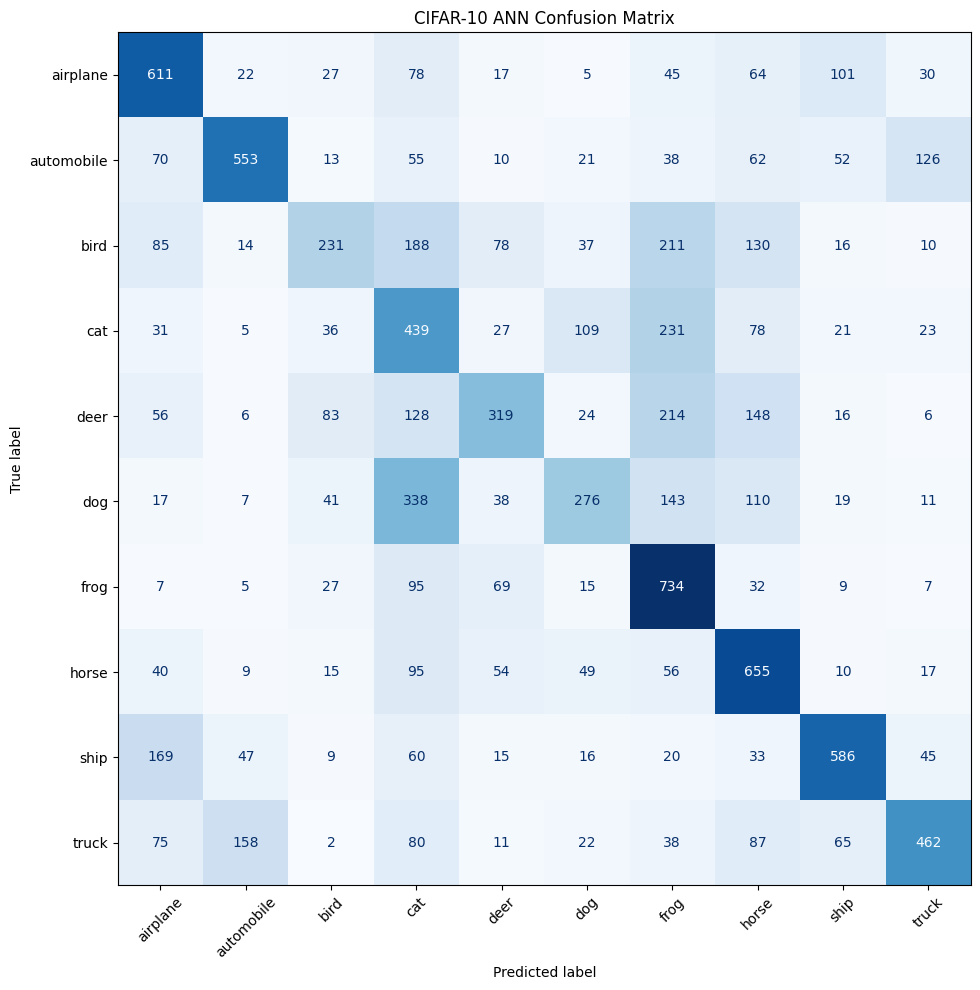

In [10]:
y_prob = model.predict(x_test, batch_size=128, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(10),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("CIFAR-10 ANN Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Plot training and validation performance

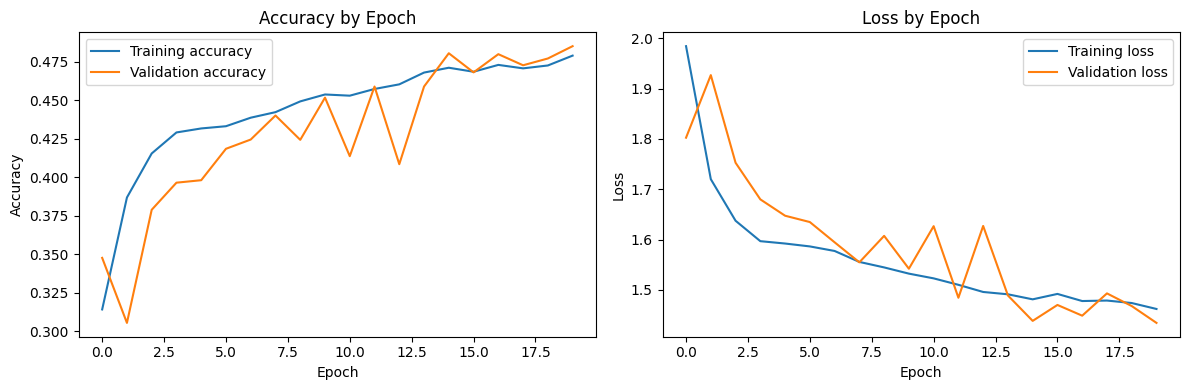

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy by Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss by Epoch")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Test the trained model with an external image

Place a JPG/PNG image in the same folder as this notebook and set `image_path` below. The image should contain one main object from these CIFAR-10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, or truck.

For Google Colab, you can instead run the optional upload cell below.

Image: C:\Users\nivas\OneDrive\Desktop\ship.jpg
Predicted class: ship
Model confidence: 96.43%

Class probabilities:
ship: 96.43%
airplane: 3.41%
automobile: 0.07%
truck: 0.05%
deer: 0.01%
cat: 0.01%
bird: 0.01%
horse: 0.00%
dog: 0.00%
frog: 0.00%


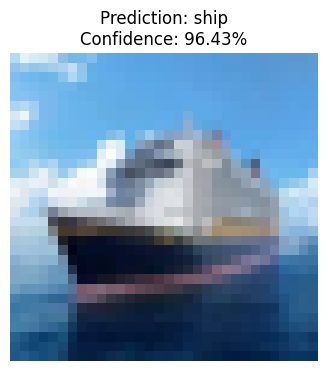

In [28]:

# --------------------------------------------------------------------------


def predict_external_image(image_path):
    """Predict one CIFAR-10 class for an external image file."""
    if not os.path.isfile(image_path):
        print("Image file not found:", image_path)
        return

    try:
        # 1. Load and convert to RGB
        image = Image.open(image_path).convert("RGB")
        resized_image = image.resize((32, 32))

        # 2. Preprocess the image to match training scale
        image_array = np.asarray(resized_image, dtype=np.float32) / 255.0
        image_batch = np.expand_dims(image_array, axis=0)

        # 3. Predict using the model
        probabilities = model.predict(image_batch, verbose=0)[0]
        predicted_index = int(np.argmax(probabilities))

        # 4. Print results to terminal
        print("Image:", image_path)
        print("Predicted class:", class_names[predicted_index])
        print(f"Model confidence: {probabilities[predicted_index] * 100:.2f}%")

        print("\nClass probabilities:")
        for i in np.argsort(probabilities)[::-1]:
            print(f"{class_names[i]}: {probabilities[i] * 100:.2f}%")

        # 5. Display the image and prediction
        plt.figure(figsize=(4, 4))
        plt.imshow(resized_image)
        plt.title(
            f"Prediction: {class_names[predicted_index]}\n"
            f"Confidence: {probabilities[predicted_index] * 100:.2f}%"
        )
        plt.axis("off")
        plt.show()

    except Exception as e:
        print("Could not process image:", e)


# Execution
image_path = r"C:\Users\nivas\OneDrive\Desktop\ship.jpg"
predict_external_image(image_path)


### Optional: Upload an image in Google Colab

Run this cell only if you are using Google Colab. It opens a file picker, then predicts the uploaded image.

In [ ]:
# Google Colab only — uncomment and run if using Colab
# from google.colab import files
# uploaded = files.upload()
# if uploaded:
#     uploaded_path = next(iter(uploaded))
#     predict_external_image(uploaded_path)

## Notes

- The model predicts only among the 10 CIFAR-10 classes.
- The confidence value is the model's softmax probability, not a guarantee of correctness.
- External photos may look different from CIFAR-10's small images, so predictions can be unreliable.
- This basic ANN is intended as a learning example. Do not expect a guaranteed accuracy such as 95%; CNN architectures are usually more suitable for image classification.